<a href="https://colab.research.google.com/github/git-konick/nft/blob/master/%D0%9A%D0%B0%D1%80%D1%82%D0%B0_%D0%B3%D0%BB%D1%83%D0%B1%D0%B8%D0%BD%D1%8B_lena.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DisparityMap - Aloe

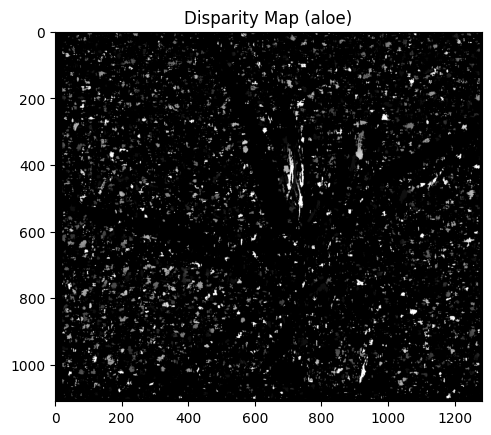

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
import urllib.request
import os

# 1. Скачиваем изображения из официального репозитория OpenCV
url_left = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/aloeL.jpg"
url_right = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/aloeR.jpg"

# url_left = "/content/aloeL.jpg"
# url_right = "/content/aloeR.jpg"

# Сохраняем во временные файлы
urllib.request.urlretrieve(url_left, "aloeL.jpg")
urllib.request.urlretrieve(url_right, "aloeR.jpg")

# 2. Загружаем их в оттенках серого
imgL = cv2.imread("aloeL.jpg", cv2.IMREAD_GRAYSCALE)
imgR = cv2.imread("aloeR.jpg", cv2.IMREAD_GRAYSCALE)

# Проверка на всякий случай
if imgL is None or imgR is None:
    raise FileNotFoundError("Не удалось загрузить изображения. Проверьте интернет-соединение.")

# 3. Создаем объект StereoBM и вычисляем карту
stereo = cv2.StereoBM_create(numDisparities=16, blockSize=15)
disparity = stereo.compute(imgL, imgR)

# 4. Визуализируем результат
plt.imshow(disparity, 'gray')
plt.title('Disparity Map (aloe)')
plt.show()

# 5. Удаляем временные файлы после показа
# os.remove("aloeL.jpg")
# os.remove("aloeR.jpg")